<a href="https://colab.research.google.com/github/anangshachatterjee/Implementation-and-Experimental-Analysis-of-Federated-Learning/blob/main/FederatedLearning_DL_24CS2009.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

import numpy as np
import matplotlib.pyplot as plt
import random
import copy

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Device configuration
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("PyTorch Version:", torch.__version__)
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


PyTorch Version: 2.14.1+cu130
Device: cuda
GPU: Tesla T4


**Working with MNIST dataset**

In [3]:

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

train_dataset = torchvision.datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = torchvision.datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

print("Training samples:", len(train_dataset))
print("Testing samples:", len(test_dataset))


100%|██████████| 9.91M/9.91M [00:00<00:00, 16.9MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 501kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.53MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 9.57MB/s]

Training samples: 60000
Testing samples: 10000


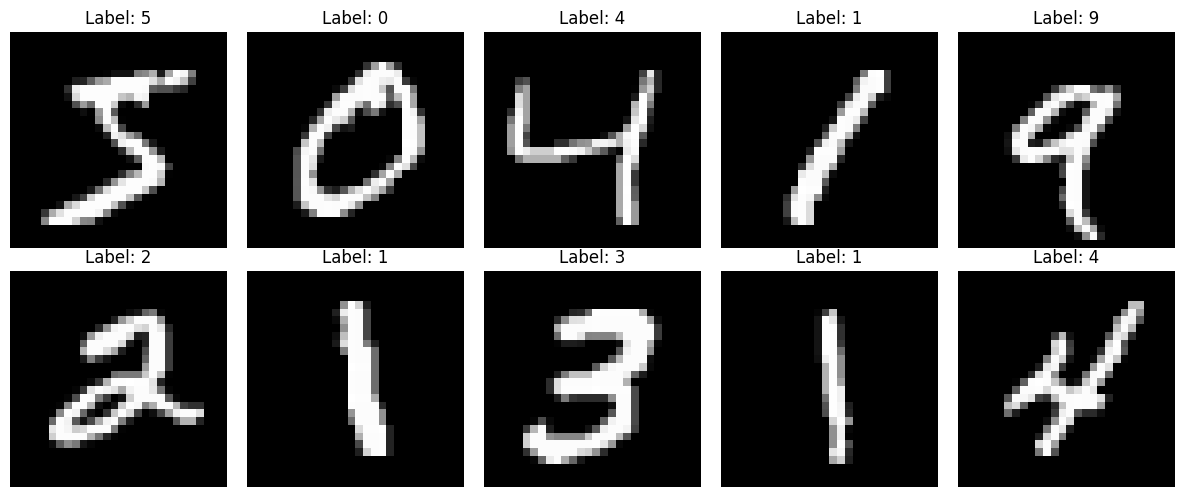

In [4]:

fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    image, label = train_dataset[i]

    ax.imshow(image.squeeze(), cmap="gray")
    ax.set_title(f"Label: {label}")
    ax.axis("off")

plt.tight_layout()
plt.show()


In [5]:

NUM_CLIENTS = 10

def iid_partition(dataset, num_clients):

    indices = np.random.permutation(len(dataset))

    client_indices = np.array_split(
        indices, num_clients
    )

    return {
        client_id: client_indices[client_id].tolist()
        for client_id in range(num_clients)
    }


client_data = iid_partition(
    train_dataset,
    NUM_CLIENTS
)

for client_id, indices in client_data.items():
    print(
        f"Client {client_id}: {len(indices)} samples"
    )


Client 0: 6000 samples
Client 1: 6000 samples
Client 2: 6000 samples
Client 3: 6000 samples
Client 4: 6000 samples
Client 5: 6000 samples
Client 6: 6000 samples
Client 7: 6000 samples
Client 8: 6000 samples
Client 9: 6000 samples


In [6]:

class MNISTModel(nn.Module):

    def __init__(self):

        super(MNISTModel, self).__init__()

        self.network = nn.Sequential(

            nn.Flatten(),

            nn.Linear(784, 200),
            nn.ReLU(),

            nn.Linear(200, 200),
            nn.ReLU(),

            nn.Linear(200, 10)

        )

    def forward(self, x):

        return self.network(x)


global_model = MNISTModel().to(device)

print(global_model)


MNISTModel(
  (network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=200, bias=True)
    (2): ReLU()
    (3): Linear(in_features=200, out_features=200, bias=True)
    (4): ReLU()
    (5): Linear(in_features=200, out_features=10, bias=True)
  )
)


In [7]:

from torch.utils.data import Subset

class LocalUpdate:

    def __init__(self, dataset, indices):

        self.loader = DataLoader(
            Subset(dataset, indices),
            batch_size=32,
            shuffle=True
        )

    def train(self, model):

        model.train()

        optimizer = optim.SGD(
            model.parameters(),
            lr=0.01
        )

        criterion = nn.CrossEntropyLoss()

        local_epochs = 2

        for epoch in range(local_epochs):

            total_loss = 0

            for images, labels in self.loader:

                images = images.to(device)
                labels = labels.to(device)

                optimizer.zero_grad()

                outputs = model(images)

                loss = criterion(outputs, labels)

                loss.backward()

                optimizer.step()

                total_loss += loss.item()

            print(
                f"Epoch {epoch+1}, "
                f"Loss: {total_loss/len(self.loader):.4f}"
            )

        return model.state_dict()


In [8]:
class LocalUpdate:

    def __init__(self, dataset, indices):

        self.loader = DataLoader(
            Subset(dataset, indices),
            batch_size=32,
            shuffle=True
        )

    def train(self, model):

        model.train()

        optimizer = optim.SGD(
            model.parameters(),
            lr=0.01
        )

        criterion = nn.CrossEntropyLoss()

        local_epochs = 2

        for epoch in range(local_epochs):

            total_loss = 0

            for images, labels in self.loader:

                images = images.to(device)
                labels = labels.to(device)

                optimizer.zero_grad()

                outputs = model(images)

                loss = criterion(outputs, labels)

                loss.backward()

                optimizer.step()

                total_loss += loss.item()

            print(
                f"Epoch {epoch+1}, "
                f"Loss: {total_loss/len(self.loader):.4f}"
            )

        return model.state_dict()


In [9]:

def fedavg(global_model, local_weights, local_sizes):

    total_samples = sum(local_sizes)

    global_weights = copy.deepcopy(
        local_weights[0]
    )

    for key in global_weights.keys():

        global_weights[key] = (
            local_weights[0][key] *
            (local_sizes[0] / total_samples)
        )

        for i in range(1, len(local_weights)):

            global_weights[key] += (
                local_weights[i][key] *
                (local_sizes[i] / total_samples)
            )

    global_model.load_state_dict(global_weights)

    return global_model


In [10]:

def evaluate_model(model, test_dataset):

    model.eval()

    test_loader = DataLoader(
        test_dataset,
        batch_size=128,
        shuffle=False
    )

    correct = 0
    total = 0
    total_loss = 0

    criterion = nn.CrossEntropyLoss()

    with torch.no_grad():

        for images, labels in test_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            total_loss += loss.item()

            predictions = outputs.argmax(dim=1)

            correct += (predictions == labels).sum().item()

            total += labels.size(0)

    accuracy = 100 * correct / total

    avg_loss = total_loss / len(test_loader)

    return avg_loss, accuracy


In [11]:

NUM_ROUNDS = 15
CLIENT_FRACTION = 0.5
NUM_CLIENTS = 10

train_losses = []
test_accuracies = []

for round_num in range(NUM_ROUNDS):

    print(f"\nCommunication Round {round_num+1}")

    # Randomly select clients
    num_selected = max(
        int(CLIENT_FRACTION * NUM_CLIENTS), 1
    )

    selected_clients = random.sample(
        range(NUM_CLIENTS),
        num_selected
    )

    local_weights = []
    local_sizes = []

    # Train selected clients
    for client_id in selected_clients:

        print(f"\nTraining Client {client_id}")

        local_model = copy.deepcopy(global_model)

        local_trainer = LocalUpdate(
            train_dataset,
            client_data[client_id]
        )

        weights = local_trainer.train(local_model)

        local_weights.append(
            copy.deepcopy(weights)
        )

        local_sizes.append(
            len(client_data[client_id])
        )

    # Aggregate client models
    global_model = fedavg(
        global_model,
        local_weights,
        local_sizes
    )

    # Evaluate global model
    loss, accuracy = evaluate_model(
        global_model,
        test_dataset
    )

    train_losses.append(loss)
    test_accuracies.append(accuracy)

    print("\nGlobal Model Results")
    print("Test Loss:", round(loss, 4))
    print("Test Accuracy:", round(accuracy, 2), "%")



Communication Round 1

Training Client 1
Epoch 1, Loss: 1.8000
Epoch 2, Loss: 0.7372

Training Client 0
Epoch 1, Loss: 1.8086
Epoch 2, Loss: 0.7450

Training Client 4
Epoch 1, Loss: 1.8205
Epoch 2, Loss: 0.7722

Training Client 9
Epoch 1, Loss: 1.8011
Epoch 2, Loss: 0.7366

Training Client 6
Epoch 1, Loss: 1.8011
Epoch 2, Loss: 0.7436

Global Model Results
Test Loss: 0.5372
Test Accuracy: 86.47 %

Communication Round 2

Training Client 2
Epoch 1, Loss: 0.4860
Epoch 2, Loss: 0.3942

Training Client 1
Epoch 1, Loss: 0.4839
Epoch 2, Loss: 0.3951

Training Client 8
Epoch 1, Loss: 0.4990
Epoch 2, Loss: 0.4093

Training Client 4
Epoch 1, Loss: 0.5114
Epoch 2, Loss: 0.4210

Training Client 3
Epoch 1, Loss: 0.4920
Epoch 2, Loss: 0.3988

Global Model Results
Test Loss: 0.3572
Test Accuracy: 89.83 %

Communication Round 3

Training Client 0
Epoch 1, Loss: 0.3588
Epoch 2, Loss: 0.3205

Training Client 9
Epoch 1, Loss: 0.3556
Epoch 2, Loss: 0.3218

Training Client 1
Epoch 1, Loss: 0.3588
Epoch 2,

**Working with CIFAR-10 dataset**

In [12]:

transform = transforms.Compose([
    transforms.ToTensor(),

    transforms.Normalize(
        (0.4914, 0.4822, 0.4465),
        (0.2470, 0.2435, 0.2616)
    )
])

train_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

print("Training samples:", len(train_dataset))
print("Testing samples:", len(test_dataset))

print("Number of classes:", len(train_dataset.classes))
print("Classes:", train_dataset.classes)


100%|██████████| 170M/170M [40:48<00:00, 69.6kB/s]


Training samples: 50000
Testing samples: 10000
Number of classes: 10
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


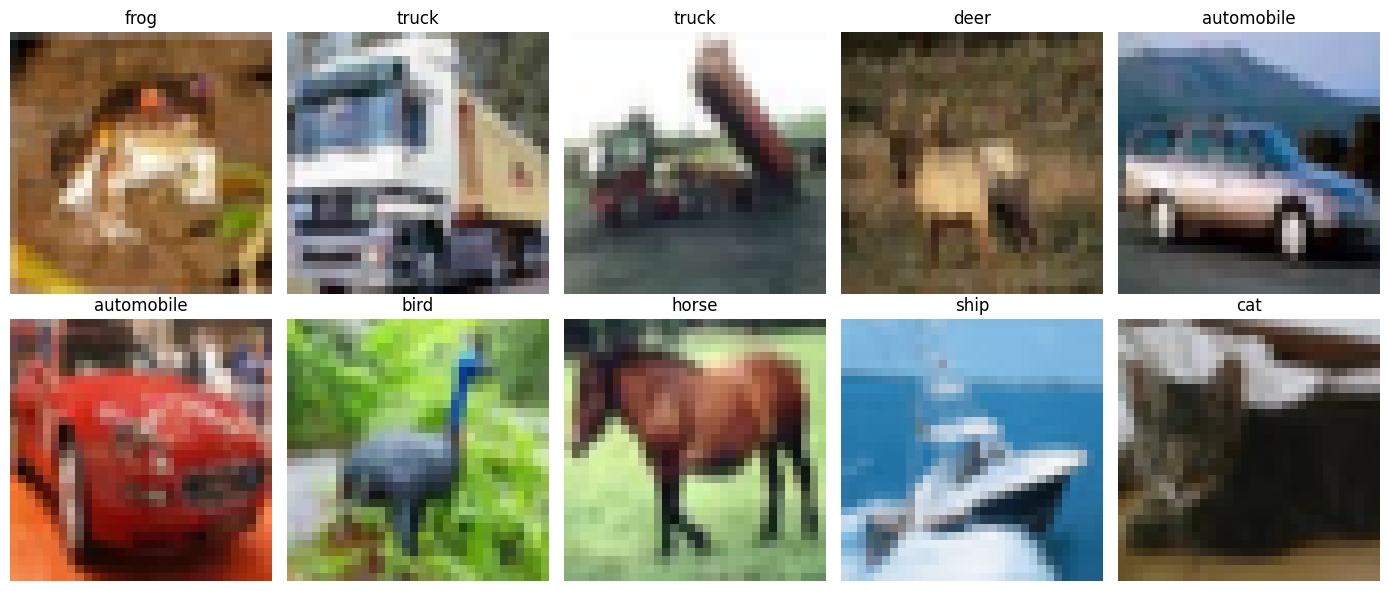

In [13]:

classes = train_dataset.classes

def show_images(dataset):

    fig, axes = plt.subplots(2, 5, figsize=(14, 6))

    mean = np.array([0.4914, 0.4822, 0.4465])
    std = np.array([0.2470, 0.2435, 0.2616])

    for i, ax in enumerate(axes.flat):

        image, label = dataset[i]

        image = image.permute(1, 2, 0).numpy()

        image = image * std + mean

        image = np.clip(image, 0, 1)

        ax.imshow(image)
        ax.set_title(classes[label])
        ax.axis("off")

    plt.tight_layout()
    plt.show()


show_images(train_dataset)


In [14]:

NUM_CLIENTS = 100

def iid_partition(dataset, num_clients):

    indices = np.random.permutation(len(dataset))

    split_indices = np.array_split(
        indices,
        num_clients
    )

    client_data = {}

    for client_id in range(num_clients):

        client_data[client_id] = (
            split_indices[client_id].tolist()
        )

    return client_data


client_data = iid_partition(
    train_dataset,
    NUM_CLIENTS
)

for client_id in range(5):

    print(
        f"Client {client_id}: "
        f"{len(client_data[client_id])} samples"
    )


Client 0: 500 samples
Client 1: 500 samples
Client 2: 500 samples
Client 3: 500 samples
Client 4: 500 samples


In [15]:


class CIFAR10_CNN(nn.Module):

    def __init__(self):

        super(CIFAR10_CNN, self).__init__()

        self.conv1 = nn.Conv2d(
            3, 32, kernel_size=3, padding=1
        )

        self.conv2 = nn.Conv2d(
            32, 64, kernel_size=3, padding=1
        )

        self.pool = nn.MaxPool2d(2, 2)

        self.fc1 = nn.Linear(
            64 * 8 * 8, 256
        )

        self.fc2 = nn.Linear(
            256, 10
        )

        self.relu = nn.ReLU()

    def forward(self, x):

        x = self.relu(self.conv1(x))
        x = self.pool(x)

        x = self.relu(self.conv2(x))
        x = self.pool(x)

        x = torch.flatten(x, 1)

        x = self.relu(self.fc1(x))

        x = self.fc2(x)

        return x


global_model = CIFAR10_CNN().to(device)

print(global_model)

print(
    "Total parameters:",
    sum(p.numel() for p in global_model.parameters())
)



CIFAR10_CNN(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=4096, out_features=256, bias=True)
  (fc2): Linear(in_features=256, out_features=10, bias=True)
  (relu): ReLU()
)
Total parameters: 1070794


In [16]:

class LocalUpdateCIFAR:

    def __init__(self, dataset, indices):

        self.loader = DataLoader(
            Subset(dataset, indices),
            batch_size=50,
            shuffle=True,
            num_workers=2,
            pin_memory=(device.type == "cuda")
        )

    def train(self, model):

        model.train()

        optimizer = optim.SGD(
            model.parameters(),
            lr=0.01
        )

        criterion = nn.CrossEntropyLoss()

        local_epochs = 5

        for epoch in range(local_epochs):

            total_loss = 0

            for images, labels in self.loader:

                images = images.to(device)
                labels = labels.to(device)

                optimizer.zero_grad()

                outputs = model(images)

                loss = criterion(outputs, labels)

                loss.backward()

                optimizer.step()

                total_loss += loss.item()

            avg_loss = total_loss / len(self.loader)

            print(
                f"Epoch {epoch+1}/{local_epochs}, "
                f"Loss: {avg_loss:.4f}"
            )

        return copy.deepcopy(model.state_dict())


In [17]:

def fedavg_cifar(global_model, local_weights, local_sizes):

    total_samples = sum(local_sizes)

    global_weights = copy.deepcopy(local_weights[0])

    for key in global_weights.keys():

        global_weights[key] = torch.zeros_like(
            local_weights[0][key]
        )

        for i in range(len(local_weights)):

            global_weights[key] += (
                local_weights[i][key] *
                (local_sizes[i] / total_samples)
            )

    global_model.load_state_dict(global_weights)

    return global_model


In [18]:

def evaluate_cifar(model, test_dataset):

    model.eval()

    test_loader = DataLoader(
        test_dataset,
        batch_size=128,
        shuffle=False,
        num_workers=2,
        pin_memory=(device.type == "cuda")
    )

    criterion = nn.CrossEntropyLoss()

    correct = 0
    total = 0
    total_loss = 0

    with torch.no_grad():

        for images, labels in test_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            total_loss += loss.item()

            predictions = torch.argmax(
                outputs, dim=1
            )

            correct += (
                predictions == labels
            ).sum().item()

            total += labels.size(0)

    accuracy = 100 * correct / total

    avg_loss = total_loss / len(test_loader)

    return avg_loss, accuracy


In [19]:

# Hyperparameters

NUM_ROUNDS = 30

NUM_CLIENTS = 100

CLIENT_FRACTION = 0.1

NUM_SELECTED = max(
    int(NUM_CLIENTS * CLIENT_FRACTION), 1
)

# Initialize global model

global_model = CIFAR10_CNN().to(device)

# Store results

cifar_train_losses = []

cifar_test_accuracies = []

# Training loop

for round_num in range(NUM_ROUNDS):

    print("\n" + "=" * 50)

    print(f"Communication Round {round_num + 1}/{NUM_ROUNDS}")

    print("=" * 50)

    # Random client selection

    selected_clients = random.sample(
        range(NUM_CLIENTS),
        NUM_SELECTED
    )

    local_weights = []

    local_sizes = []

    # Local client training

    for client_id in selected_clients:

        print(f"\nTraining Client {client_id}")

        local_model = copy.deepcopy(
            global_model
        )

        local_trainer = LocalUpdateCIFAR(
            train_dataset,
            client_data[client_id]
        )

        weights = local_trainer.train(
            local_model
        )

        local_weights.append(weights)

        local_sizes.append(
            len(client_data[client_id])
        )

        del local_model

    # Global model aggregation

    global_model = fedavg_cifar(
        global_model,
        local_weights,
        local_sizes
    )

    # Evaluate global model

    test_loss, test_accuracy = evaluate_cifar(
        global_model,
        test_dataset
    )

    cifar_train_losses.append(test_loss)

    cifar_test_accuracies.append(test_accuracy)

    print("\nGlobal Model Evaluation")

    print("Test Loss:", round(test_loss, 4))

    print("Test Accuracy:", round(test_accuracy, 2), "%")

    print("=" * 50)

    del local_weights

    if torch.cuda.is_available():
        torch.cuda.empty_cache()



Communication Round 1/30

Training Client 31
Epoch 1/5, Loss: 2.2955
Epoch 2/5, Loss: 2.2732
Epoch 3/5, Loss: 2.2524
Epoch 4/5, Loss: 2.2330
Epoch 5/5, Loss: 2.2112

Training Client 20
Epoch 1/5, Loss: 2.2973
Epoch 2/5, Loss: 2.2721
Epoch 3/5, Loss: 2.2483
Epoch 4/5, Loss: 2.2253
Epoch 5/5, Loss: 2.1999

Training Client 59
Epoch 1/5, Loss: 2.3006
Epoch 2/5, Loss: 2.2795
Epoch 3/5, Loss: 2.2607
Epoch 4/5, Loss: 2.2459
Epoch 5/5, Loss: 2.2280

Training Client 48
Epoch 1/5, Loss: 2.2956
Epoch 2/5, Loss: 2.2710
Epoch 3/5, Loss: 2.2470
Epoch 4/5, Loss: 2.2226
Epoch 5/5, Loss: 2.1971

Training Client 34
Epoch 1/5, Loss: 2.2977
Epoch 2/5, Loss: 2.2785
Epoch 3/5, Loss: 2.2620
Epoch 4/5, Loss: 2.2449
Epoch 5/5, Loss: 2.2277

Training Client 81
Epoch 1/5, Loss: 2.2977
Epoch 2/5, Loss: 2.2764
Epoch 3/5, Loss: 2.2590
Epoch 4/5, Loss: 2.2406
Epoch 5/5, Loss: 2.2218

Training Client 88
Epoch 1/5, Loss: 2.2993
Epoch 2/5, Loss: 2.2833
Epoch 3/5, Loss: 2.2665
Epoch 4/5, Loss: 2.2506
Epoch 5/5, Loss: 2

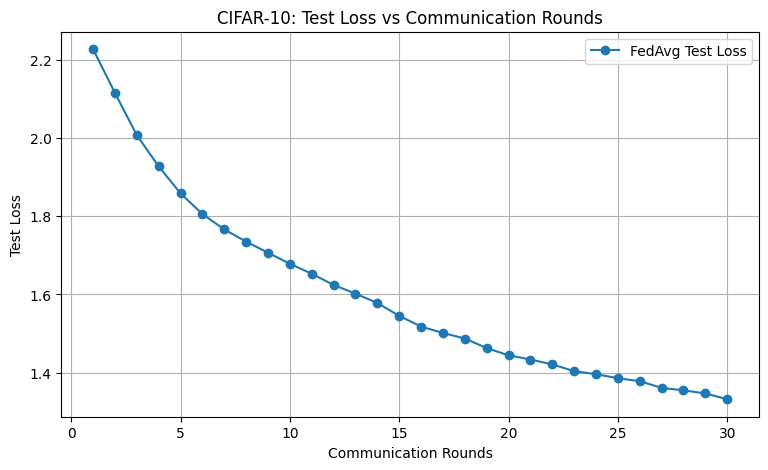

In [20]:

plt.figure(figsize=(9, 5))

plt.plot(
    range(1, NUM_ROUNDS + 1),
    cifar_train_losses,
    marker='o',
    label='FedAvg Test Loss'
)

plt.xlabel("Communication Rounds")

plt.ylabel("Test Loss")

plt.title("CIFAR-10: Test Loss vs Communication Rounds")

plt.legend()

plt.grid(True)

plt.show()


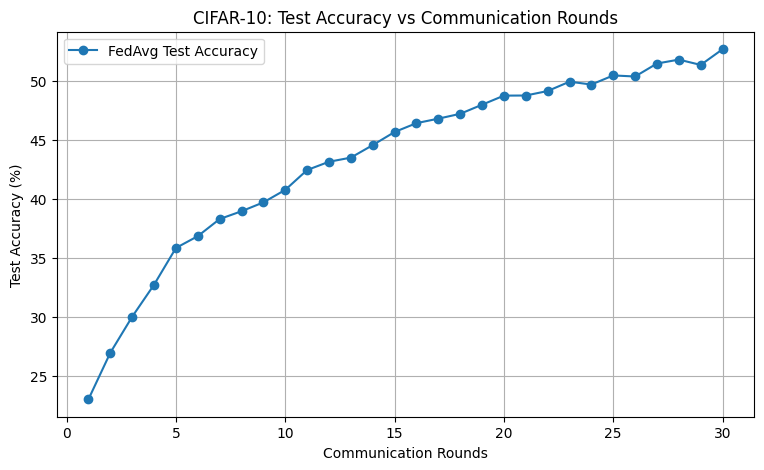

In [21]:

plt.figure(figsize=(9, 5))

plt.plot(
    range(1, NUM_ROUNDS + 1),
    cifar_test_accuracies,
    marker='o',
    label='FedAvg Test Accuracy'
)

plt.xlabel("Communication Rounds")

plt.ylabel("Test Accuracy (%)")

plt.title("CIFAR-10: Test Accuracy vs Communication Rounds")

plt.legend()

plt.grid(True)

plt.show()


In [22]:

def class_accuracy(model, test_dataset):

    model.eval()

    correct = [0] * 10

    total = [0] * 10

    loader = DataLoader(
        test_dataset,
        batch_size=128,
        shuffle=False
    )

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            predictions = outputs.argmax(dim=1)

            for i in range(len(labels)):

                label = labels[i].item()

                total[label] += 1

                if predictions[i] == labels[i]:

                    correct[label] += 1

    for i in range(10):

        accuracy = 100 * correct[i] / total[i]

        print(
            f"{classes[i]}: {accuracy:.2f}%"
        )


class_accuracy(global_model, test_dataset)


airplane: 53.30%
automobile: 63.40%
bird: 35.30%
cat: 36.90%
deer: 35.30%
dog: 48.00%
frog: 67.30%
horse: 61.10%
ship: 67.00%
truck: 59.40%


In [23]:

torch.save(
    global_model.state_dict(),
    "cifar10_fedavg_model.pth"
)

print("Model saved successfully!")


from google.colab import files

files.download("cifar10_fedavg_model.pth")


Model saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Centralized SGD using CIFAR-10**

In [24]:

centralized_model = CIFAR10_CNN().to(device)

print(centralized_model)


CIFAR10_CNN(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=4096, out_features=256, bias=True)
  (fc2): Linear(in_features=256, out_features=10, bias=True)
  (relu): ReLU()
)


In [25]:

centralized_train_loader = DataLoader(
    train_dataset,
    batch_size=50,
    shuffle=True,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

centralized_test_loader = DataLoader(
    test_dataset,
    batch_size=128,
    shuffle=False,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

print("Training batches:", len(centralized_train_loader))
print("Testing batches:", len(centralized_test_loader))


Training batches: 1000
Testing batches: 79


In [26]:

def train_centralized_sgd(
    model,
    train_loader,
    test_dataset,
    epochs=30,
    learning_rate=0.01
):

    criterion = nn.CrossEntropyLoss()

    optimizer = optim.SGD(
        model.parameters(),
        lr=learning_rate
    )

    train_losses = []
    test_losses = []
    test_accuracies = []

    for epoch in range(epochs):

        model.train()

        running_loss = 0

        for images, labels in train_loader:

            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)

            loss = criterion(outputs, labels)

            loss.backward()

            optimizer.step()

            running_loss += loss.item()

        avg_train_loss = (
            running_loss / len(train_loader)
        )

        test_loss, test_accuracy = evaluate_cifar(
            model,
            test_dataset
        )

        train_losses.append(avg_train_loss)
        test_losses.append(test_loss)
        test_accuracies.append(test_accuracy)

        print(
            f"Epoch [{epoch+1}/{epochs}] "
            f"Train Loss: {avg_train_loss:.4f} "
            f"Test Loss: {test_loss:.4f} "
            f"Test Accuracy: {test_accuracy:.2f}%"
        )

    return train_losses, test_losses, test_accuracies


In [27]:

centralized_results = train_centralized_sgd(
    model=centralized_model,
    train_loader=centralized_train_loader,
    test_dataset=test_dataset,
    epochs=30,
    learning_rate=0.01
)

centralized_train_losses = centralized_results[0]
centralized_test_losses = centralized_results[1]
centralized_accuracies = centralized_results[2]


Epoch [1/30] Train Loss: 1.8155 Test Loss: 1.4842 Test Accuracy: 46.76%
Epoch [2/30] Train Loss: 1.4002 Test Loss: 1.3067 Test Accuracy: 53.47%
Epoch [3/30] Train Loss: 1.2453 Test Loss: 1.1915 Test Accuracy: 58.36%
Epoch [4/30] Train Loss: 1.1338 Test Loss: 1.1077 Test Accuracy: 60.83%
Epoch [5/30] Train Loss: 1.0441 Test Loss: 1.0623 Test Accuracy: 62.72%
Epoch [6/30] Train Loss: 0.9639 Test Loss: 1.0090 Test Accuracy: 64.07%
Epoch [7/30] Train Loss: 0.8962 Test Loss: 0.9318 Test Accuracy: 67.50%
Epoch [8/30] Train Loss: 0.8382 Test Loss: 0.9203 Test Accuracy: 68.00%
Epoch [9/30] Train Loss: 0.7795 Test Loss: 0.8839 Test Accuracy: 69.05%
Epoch [10/30] Train Loss: 0.7278 Test Loss: 0.8547 Test Accuracy: 70.69%
Epoch [11/30] Train Loss: 0.6793 Test Loss: 0.8448 Test Accuracy: 70.88%
Epoch [12/30] Train Loss: 0.6256 Test Loss: 0.8252 Test Accuracy: 71.95%
Epoch [13/30] Train Loss: 0.5763 Test Loss: 0.8333 Test Accuracy: 72.05%
Epoch [14/30] Train Loss: 0.5255 Test Loss: 0.8314 Test Accu

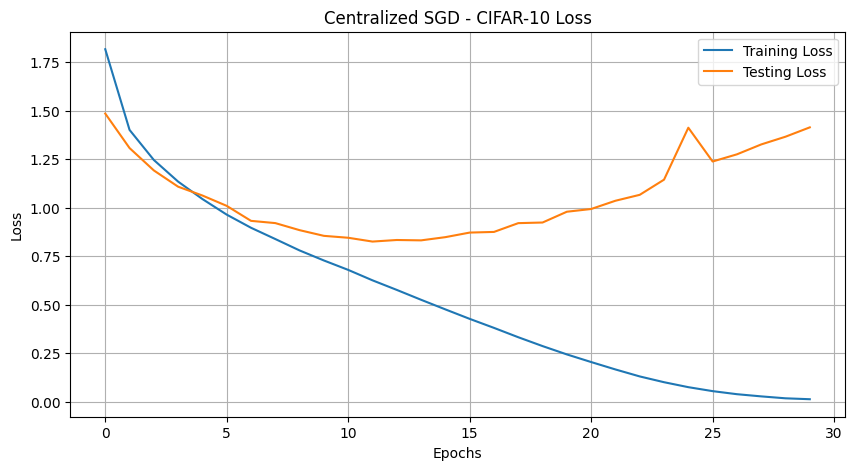

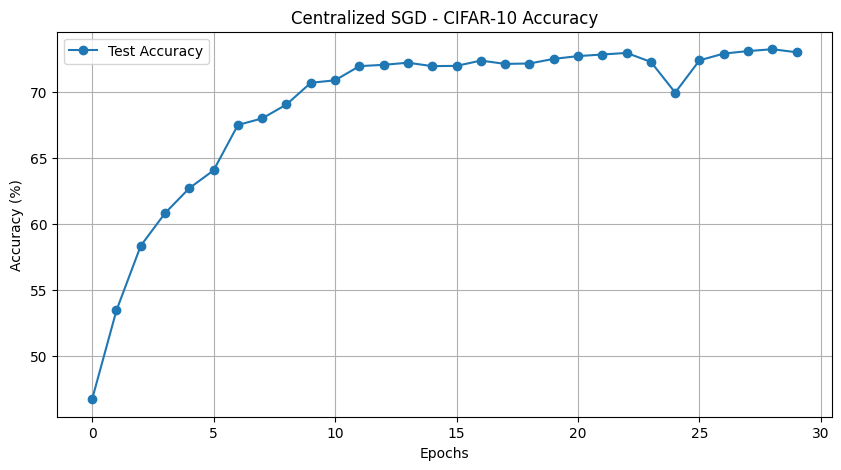

In [28]:

plt.figure(figsize=(10, 5))

plt.plot(
    centralized_train_losses,
    label="Training Loss"
)

plt.plot(
    centralized_test_losses,
    label="Testing Loss"
)

plt.xlabel("Epochs")
plt.ylabel("Loss")

plt.title("Centralized SGD - CIFAR-10 Loss")

plt.legend()
plt.grid(True)
plt.show()


plt.figure(figsize=(10, 5))

plt.plot(
    centralized_accuracies,
    marker='o',
    label="Test Accuracy"
)

plt.xlabel("Epochs")
plt.ylabel("Accuracy (%)")

plt.title("Centralized SGD - CIFAR-10 Accuracy")

plt.legend()
plt.grid(True)
plt.show()


**FedSGD using CIFAR-10**

In [29]:

NUM_ROUNDS_FEDSGD = 30

NUM_CLIENTS = 100

CLIENT_FRACTION = 0.1

NUM_SELECTED = max(
    int(NUM_CLIENTS * CLIENT_FRACTION), 1
)

LEARNING_RATE = 0.01

print("Number of clients:", NUM_CLIENTS)
print("Selected clients per round:", NUM_SELECTED)
print("Client fraction:", CLIENT_FRACTION)
print("Learning rate:", LEARNING_RATE)


Number of clients: 100
Selected clients per round: 10
Client fraction: 0.1
Learning rate: 0.01


In [30]:

def compute_client_gradient(
    global_model,
    dataset,
    indices
):

    global_model.train()

    loader = DataLoader(
        Subset(dataset, indices),
        batch_size=len(indices),
        shuffle=False
    )

    criterion = nn.CrossEntropyLoss(
        reduction='sum'
    )

    global_model.zero_grad(set_to_none=True)

    total_samples = 0

    for images, labels in loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = global_model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        total_samples += labels.size(0)

    # Average gradients over local dataset

    local_gradients = {}

    for name, parameter in global_model.named_parameters():

        local_gradients[name] = (
            parameter.grad.detach().clone() / total_samples
        )

    return local_gradients, total_samples


In [31]:

def aggregate_gradients(
    global_model,
    client_gradients,
    client_sizes
):

    total_samples = sum(client_sizes)

    aggregated_gradients = {}

    for name, parameter in global_model.named_parameters():

        aggregated_gradients[name] = torch.zeros_like(
            parameter
        )

        for i in range(len(client_gradients)):

            weight = client_sizes[i] / total_samples

            aggregated_gradients[name] += (
                client_gradients[i][name] * weight
            )

    return aggregated_gradients


In [32]:

def update_global_model(
    global_model,
    aggregated_gradients,
    learning_rate
):

    with torch.no_grad():

        for name, parameter in global_model.named_parameters():

            parameter -= (
                learning_rate *
                aggregated_gradients[name]
            )

    return global_model


In [33]:

# Initialize global model

fedsgd_model = CIFAR10_CNN().to(device)

# Store results

fedsgd_test_losses = []

fedsgd_test_accuracies = []

# Communication rounds

for round_num in range(NUM_ROUNDS_FEDSGD):

    print("\n" + "=" * 50)

    print(
        f"FedSGD Round {round_num + 1}/"
        f"{NUM_ROUNDS_FEDSGD}"
    )

    print("=" * 50)

    # Random client selection

    selected_clients = random.sample(
        range(NUM_CLIENTS),
        NUM_SELECTED
    )

    client_gradients = []

    client_sizes = []

    # Each client calculates its local gradient

    for client_id in selected_clients:

        print(f"Calculating gradient: Client {client_id}")

        gradients, sample_count = compute_client_gradient(
            fedsgd_model,
            train_dataset,
            client_data[client_id]
        )

        client_gradients.append(gradients)

        client_sizes.append(sample_count)

    # Server aggregates gradients

    aggregated_gradients = aggregate_gradients(
        fedsgd_model,
        client_gradients,
        client_sizes
    )

    # Update global model

    fedsgd_model = update_global_model(
        fedsgd_model,
        aggregated_gradients,
        LEARNING_RATE
    )

    # Evaluate global model

    test_loss, test_accuracy = evaluate_cifar(
        fedsgd_model,
        test_dataset
    )

    fedsgd_test_losses.append(test_loss)

    fedsgd_test_accuracies.append(test_accuracy)

    print("\nGlobal Model Evaluation")

    print("Test Loss:", round(test_loss, 4))

    print("Test Accuracy:", round(test_accuracy, 2), "%")

    print("=" * 50)

    del client_gradients
    del aggregated_gradients

    if torch.cuda.is_available():
        torch.cuda.empty_cache()



FedSGD Round 1/30
Calculating gradient: Client 69
Calculating gradient: Client 90
Calculating gradient: Client 38
Calculating gradient: Client 78
Calculating gradient: Client 83
Calculating gradient: Client 67
Calculating gradient: Client 1
Calculating gradient: Client 85
Calculating gradient: Client 70
Calculating gradient: Client 84

Global Model Evaluation
Test Loss: 2.3018
Test Accuracy: 10.14 %

FedSGD Round 2/30
Calculating gradient: Client 13
Calculating gradient: Client 17
Calculating gradient: Client 33
Calculating gradient: Client 14
Calculating gradient: Client 95
Calculating gradient: Client 70
Calculating gradient: Client 19
Calculating gradient: Client 34
Calculating gradient: Client 36
Calculating gradient: Client 77

Global Model Evaluation
Test Loss: 2.3007
Test Accuracy: 10.33 %

FedSGD Round 3/30
Calculating gradient: Client 26
Calculating gradient: Client 91
Calculating gradient: Client 43
Calculating gradient: Client 87
Calculating gradient: Client 81
Calculating 

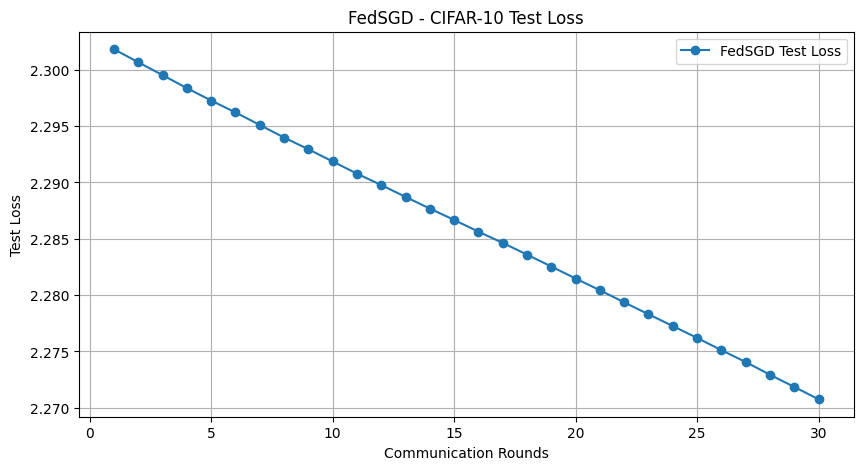

In [34]:

plt.figure(figsize=(10, 5))

plt.plot(
    range(1, NUM_ROUNDS_FEDSGD + 1),
    fedsgd_test_losses,
    marker='o',
    label='FedSGD Test Loss'
)

plt.xlabel("Communication Rounds")
plt.ylabel("Test Loss")

plt.title("FedSGD - CIFAR-10 Test Loss")

plt.legend()
plt.grid(True)
plt.show()


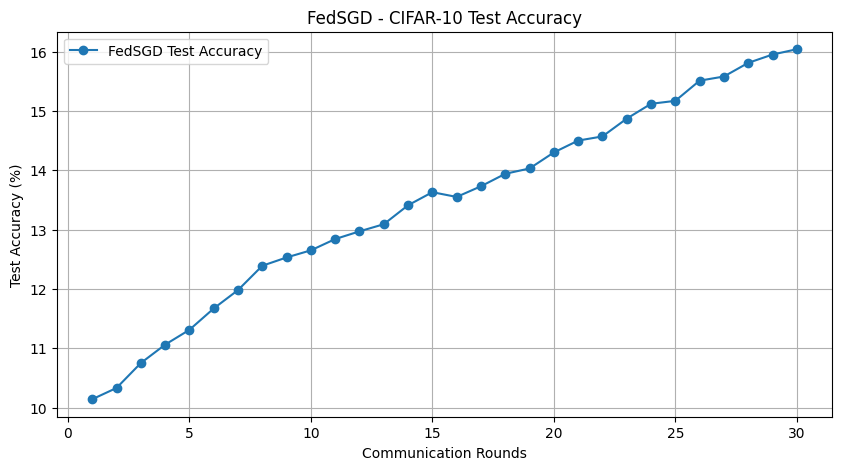

In [35]:

plt.figure(figsize=(10, 5))

plt.plot(
    range(1, NUM_ROUNDS_FEDSGD + 1),
    fedsgd_test_accuracies,
    marker='o',
    label='FedSGD Test Accuracy'
)

plt.xlabel("Communication Rounds")
plt.ylabel("Test Accuracy (%)")

plt.title("FedSGD - CIFAR-10 Test Accuracy")

plt.legend()
plt.grid(True)
plt.show()


**Final Comparision between FedAVG, FedSGD and Centralized SGD**

In [36]:

import pandas as pd

comparison = pd.DataFrame({

    "Algorithm": [
        "Centralized SGD",
        "FedSGD",
        "FedAvg"
    ],

    "Final Test Loss": [
        centralized_test_losses[-1],
        fedsgd_test_losses[-1],
        cifar_train_losses[-1]
    ],

    "Final Test Accuracy (%)": [
        centralized_accuracies[-1],
        fedsgd_test_accuracies[-1],
        cifar_test_accuracies[-1]
    ]
})

print(comparison.to_string(index=False))


      Algorithm  Final Test Loss  Final Test Accuracy (%)
Centralized SGD         1.413240                    73.00
         FedSGD         2.270763                    16.04
         FedAvg         1.331623                    52.70


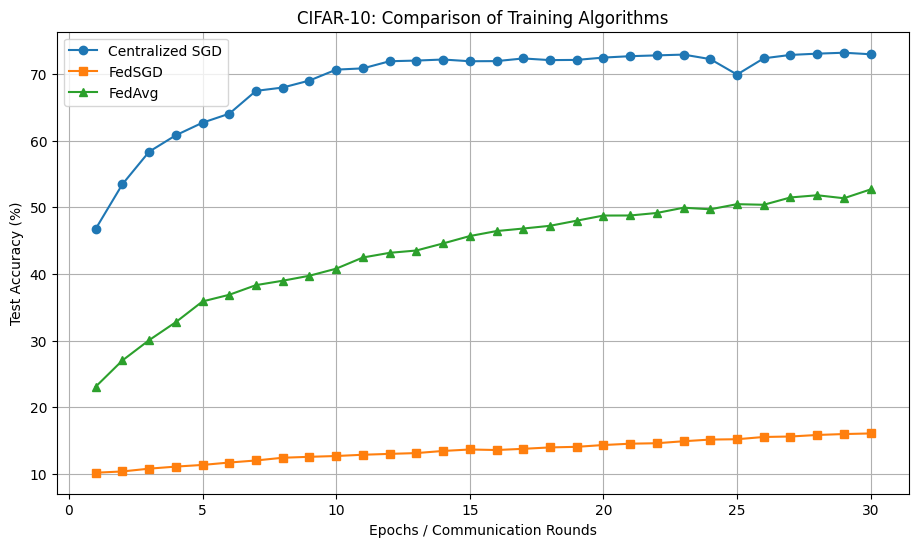

In [37]:

plt.figure(figsize=(11, 6))

plt.plot(
    range(1, len(centralized_accuracies) + 1),
    centralized_accuracies,
    label="Centralized SGD",
    marker='o'
)

plt.plot(
    range(1, len(fedsgd_test_accuracies) + 1),
    fedsgd_test_accuracies,
    label="FedSGD",
    marker='s'
)

plt.plot(
    range(1, len(cifar_test_accuracies) + 1),
    cifar_test_accuracies,
    label="FedAvg",
    marker='^'
)

plt.xlabel("Epochs / Communication Rounds")

plt.ylabel("Test Accuracy (%)")

plt.title("CIFAR-10: Comparison of Training Algorithms")

plt.legend()

plt.grid(True)

plt.show()


**Non IID partitioning using CIFAR-10**

In [38]:

import numpy as np

def dirichlet_partition(dataset, num_clients, alpha=0.5,
                        min_samples_per_client=50, seed=42):

    rng = np.random.default_rng(seed)

    labels = np.array(dataset.targets)
    num_classes = len(np.unique(labels))

    client_indices = {
        client_id: [] for client_id in range(num_clients)
    }

    min_size = 0

    while min_size < min_samples_per_client:

        client_indices = {
            client_id: [] for client_id in range(num_clients)
        }

        for class_id in range(num_classes):

            # Get indices belonging to this class
            class_indices = np.where(labels == class_id)[0]

            # Shuffle the indices
            rng.shuffle(class_indices)

            # Generate class proportions for all clients
            proportions = rng.dirichlet(
                np.repeat(alpha, num_clients)
            )

            # Avoid assigning more data to clients
            # that have already reached the average size
            proportions = np.array([
                p * (len(client_indices[i]) < len(dataset) / num_clients)
                for i, p in enumerate(proportions)
            ])

            proportions = proportions / proportions.sum()

            # Divide class indices among clients
            split_points = (
                np.cumsum(proportions)[:-1] * len(class_indices)
            ).astype(int)

            class_splits = np.split(class_indices, split_points)

            for client_id, indices in enumerate(class_splits):
                client_indices[client_id].extend(indices.tolist())

        min_size = min(
            len(indices) for indices in client_indices.values()
        )

    # Shuffle each client's final collection of indices
    for client_id in range(num_clients):
        rng.shuffle(client_indices[client_id])

    return client_indices


# Configuration
NUM_CLIENTS = 100
ALPHA = 0.5

# Generate Non-IID partitions
client_indices = dirichlet_partition(
    train_dataset,
    num_clients=NUM_CLIENTS,
    alpha=ALPHA
)

print("Non-IID partitioning completed!")
print("Number of clients:", len(client_indices))
print("Total samples distributed:",
      sum(len(indices) for indices in client_indices.values()))
print("Smallest client dataset:",
      min(len(indices) for indices in client_indices.values()))
print("Largest client dataset:",
      max(len(indices) for indices in client_indices.values()))


Non-IID partitioning completed!
Number of clients: 100
Total samples distributed: 50000
Smallest client dataset: 151
Largest client dataset: 913


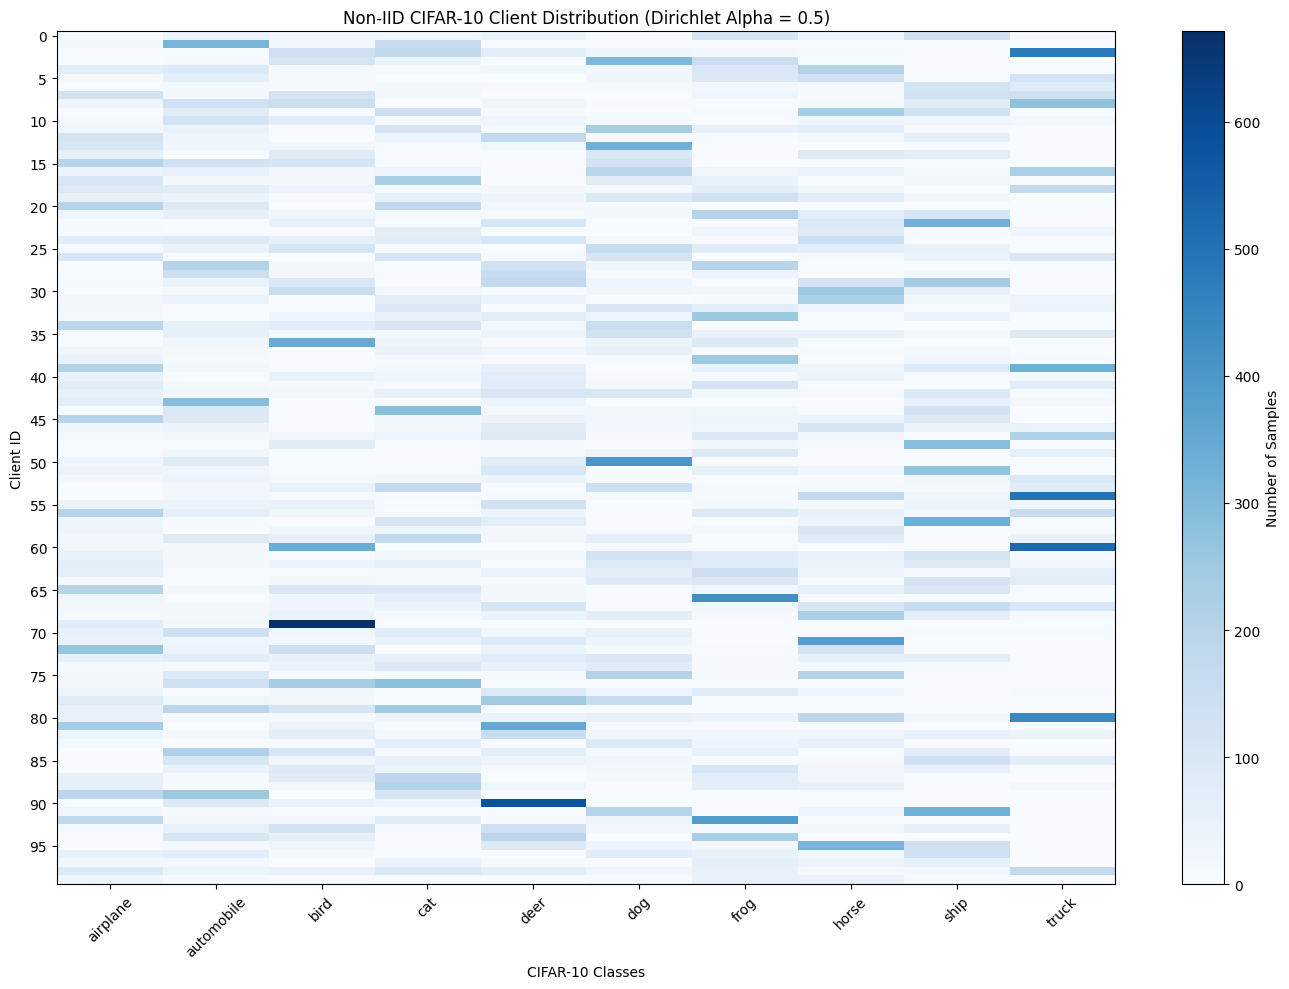

In [39]:

import matplotlib.pyplot as plt
import numpy as np

classes = train_dataset.classes

# Create a matrix: rows = clients, columns = classes
class_distribution = np.zeros((NUM_CLIENTS, len(classes)))

for client_id, indices in client_indices.items():

    client_labels = np.array(train_dataset.targets)[indices]

    for class_id in range(len(classes)):
        class_distribution[client_id, class_id] = np.sum(
            client_labels == class_id
        )

# Plot heatmap
plt.figure(figsize=(14, 10))

plt.imshow(
    class_distribution,
    aspect="auto",
    cmap="Blues",
    interpolation="nearest"
)

plt.colorbar(label="Number of Samples")

plt.xlabel("CIFAR-10 Classes")
plt.ylabel("Client ID")

plt.xticks(
    ticks=np.arange(len(classes)),
    labels=classes,
    rotation=45
)

plt.yticks(np.arange(0, NUM_CLIENTS, 5))

plt.title(
    f"Non-IID CIFAR-10 Client Distribution "
    f"(Dirichlet Alpha = {ALPHA})"
)

plt.tight_layout()
plt.show()


In [40]:

for client_id in range(10):

    indices = client_indices[client_id]
    client_labels = np.array(train_dataset.targets)[indices]

    print(f"\nClient {client_id}")
    print("Total samples:", len(indices))

    for class_id, class_name in enumerate(classes):

        count = np.sum(client_labels == class_id)

        if count > 0:
            print(f"{class_name}: {count}")



Client 0
Total samples: 394
airplane: 2
automobile: 32
bird: 24
cat: 24
deer: 35
dog: 2
frog: 109
horse: 28
ship: 131
truck: 7

Client 1
Total samples: 504
airplane: 11
automobile: 312
bird: 20
cat: 161

Client 2
Total samples: 913
bird: 139
cat: 178
deer: 71
dog: 27
frog: 14
horse: 9
ship: 1
truck: 474

Client 3
Total samples: 620
airplane: 1
automobile: 10
bird: 117
cat: 35
deer: 1
dog: 303
frog: 153

Client 4
Total samples: 522
airplane: 63
automobile: 90
bird: 7
cat: 9
deer: 24
dog: 19
frog: 99
horse: 211

Client 5
Total samples: 458
airplane: 7
automobile: 66
bird: 6
cat: 1
deer: 1
dog: 22
frog: 92
horse: 141
ship: 1
truck: 121

Client 6
Total samples: 267
automobile: 11
bird: 5
cat: 11
deer: 6
dog: 10
frog: 17
horse: 6
ship: 124
truck: 77

Client 7
Total samples: 573
airplane: 131
automobile: 15
bird: 118
cat: 12
dog: 2
frog: 27
ship: 129
truck: 139

Client 8
Total samples: 711
airplane: 30
automobile: 134
bird: 152
deer: 23
dog: 4
frog: 5
horse: 10
ship: 77
truck: 276

Client 9

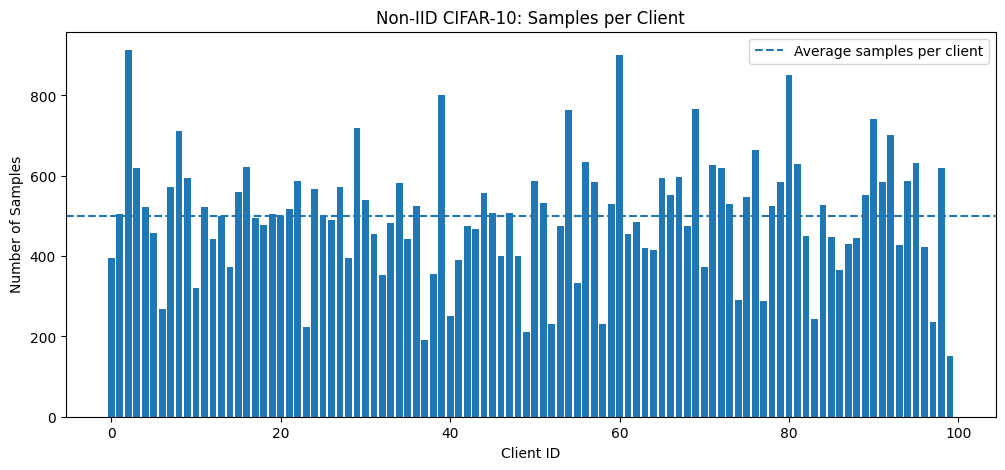

In [41]:

client_sizes = [
    len(client_indices[i]) for i in range(NUM_CLIENTS)
]

plt.figure(figsize=(12, 5))

plt.bar(range(NUM_CLIENTS), client_sizes)

plt.axhline(
    y=len(train_dataset) / NUM_CLIENTS,
    linestyle="--",
    label="Average samples per client"
)

plt.xlabel("Client ID")
plt.ylabel("Number of Samples")
plt.title("Non-IID CIFAR-10: Samples per Client")
plt.legend()
plt.show()


In [42]:
indices = client_indices[client_id]

In [43]:
global_model = CIFAR10_CNN().to(device)

# Run your existing CIFAR-10 FedAvg training loop again

In [45]:

import copy
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import DataLoader, Subset

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

NUM_CLIENTS = 100
NUM_ROUNDS = 30
CLIENT_FRACTION = 0.1
LOCAL_EPOCHS = 5
BATCH_SIZE = 50
LEARNING_RATE = 0.01


Device: cuda


In [46]:

def iid_partition(dataset, num_clients, seed=42):

    rng = np.random.default_rng(seed)

    indices = rng.permutation(len(dataset))
    splits = np.array_split(indices, num_clients)

    return {
        i: splits[i].tolist()
        for i in range(num_clients)
    }


def dirichlet_partition(
    dataset,
    num_clients,
    alpha=0.5,
    min_samples_per_client=50,
    seed=42
):

    rng = np.random.default_rng(seed)
    labels = np.array(dataset.targets)

    num_classes = len(np.unique(labels))

    for attempt in range(1000):

        client_indices = {
            i: [] for i in range(num_clients)
        }

        for class_id in range(num_classes):

            class_indices = np.where(labels == class_id)[0]
            rng.shuffle(class_indices)

            proportions = rng.dirichlet(
                np.repeat(alpha, num_clients)
            )

            # Balance client dataset sizes approximately
            proportions = np.array([
                p * (
                    len(client_indices[i])
                    < len(dataset) / num_clients
                )
                for i, p in enumerate(proportions)
            ])

            if proportions.sum() == 0:
                continue

            proportions = proportions / proportions.sum()

            split_points = (
                np.cumsum(proportions)[:-1]
                * len(class_indices)
            ).astype(int)

            splits = np.split(class_indices, split_points)

            for i, split in enumerate(splits):
                client_indices[i].extend(split.tolist())

        sizes = [
            len(client_indices[i])
            for i in range(num_clients)
        ]

        if min(sizes) >= min_samples_per_client:
            for i in range(num_clients):
                rng.shuffle(client_indices[i])

            return client_indices

    raise RuntimeError(
        "Could not generate a valid partition. "
        "Try a smaller minimum sample requirement or larger alpha."
    )


In [47]:

def evaluate_model(model, test_dataset, batch_size=128):

    model.eval()

    test_loader = DataLoader(
        test_dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=0
    )

    criterion = nn.CrossEntropyLoss(reduction="sum")

    total_loss = 0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in test_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            total_loss += loss.item()

            predictions = torch.argmax(outputs, dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    average_loss = total_loss / total
    accuracy = 100 * correct / total

    return average_loss, accuracy


In [48]:

def train_local_model(
    global_model,
    dataset,
    indices,
    local_epochs,
    batch_size,
    learning_rate
):

    local_model = copy.deepcopy(global_model).to(device)

    loader = DataLoader(
        Subset(dataset, indices),
        batch_size=batch_size,
        shuffle=True,
        num_workers=0
    )

    criterion = nn.CrossEntropyLoss()

    optimizer = optim.SGD(
        local_model.parameters(),
        lr=learning_rate
    )

    local_model.train()

    for epoch in range(local_epochs):

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = local_model(images)

            loss = criterion(outputs, labels)

            loss.backward()

            optimizer.step()

    local_weights = copy.deepcopy(
        local_model.state_dict()
    )

    return local_weights


In [49]:

def aggregate_weights(local_weights, local_sizes):

    total_samples = sum(local_sizes)

    global_weights = copy.deepcopy(local_weights[0])

    for key in global_weights:

        if torch.is_floating_point(global_weights[key]):

            global_weights[key] = torch.zeros_like(
                global_weights[key]
            )

            for i in range(len(local_weights)):

                weight = local_sizes[i] / total_samples

                global_weights[key] += (
                    local_weights[i][key] * weight
                )

    return global_weights


In [50]:

def run_fedavg(
    model_class,
    train_dataset,
    test_dataset,
    partition,
    initial_weights,
    rounds=30,
    client_fraction=0.1,
    local_epochs=5,
    batch_size=50,
    learning_rate=0.01
):

    global_model = model_class().to(device)

    global_model.load_state_dict(
        copy.deepcopy(initial_weights)
    )

    num_clients = len(partition)

    num_selected = max(
        1, int(client_fraction * num_clients)
    )

    losses = []
    accuracies = []

    for round_num in range(rounds):

        selected_clients = random.sample(
            range(num_clients),
            num_selected
        )

        local_weights = []
        local_sizes = []

        for client_id in selected_clients:

            indices = partition[client_id]

            weights = train_local_model(
                global_model,
                train_dataset,
                indices,
                local_epochs,
                batch_size,
                learning_rate
            )

            local_weights.append(weights)
            local_sizes.append(len(indices))

            del weights

        # Server aggregation
        new_weights = aggregate_weights(
            local_weights,
            local_sizes
        )

        global_model.load_state_dict(new_weights)

        # Evaluate global model
        test_loss, test_accuracy = evaluate_model(
            global_model,
            test_dataset
        )

        losses.append(test_loss)
        accuracies.append(test_accuracy)

        print(
            f"Round {round_num + 1}/{rounds} | "
            f"Loss: {test_loss:.4f} | "
            f"Accuracy: {test_accuracy:.2f}%"
        )

    return global_model, losses, accuracies


**IID vs Non-IID FedAvg**

In [51]:

cifar_iid_partition = iid_partition(
    train_dataset,
    NUM_CLIENTS,
    seed=SEED
)

cifar_noniid_partition = dirichlet_partition(
    train_dataset,
    NUM_CLIENTS,
    alpha=0.5,
    min_samples_per_client=50,
    seed=SEED
)

print("IID total samples:",
      sum(len(v) for v in cifar_iid_partition.values()))

print("Non-IID total samples:",
      sum(len(v) for v in cifar_noniid_partition.values()))


IID total samples: 50000
Non-IID total samples: 50000


In [52]:

initial_cifar_model = CIFAR10_CNN()

initial_cifar_weights = copy.deepcopy(
    initial_cifar_model.state_dict()
)

del initial_cifar_model


In [53]:

cifar_iid_model, cifar_iid_losses, cifar_iid_accuracies = run_fedavg(
    model_class=CIFAR10_CNN,
    train_dataset=train_dataset,
    test_dataset=test_dataset,
    partition=cifar_iid_partition,
    initial_weights=initial_cifar_weights,
    rounds=NUM_ROUNDS,
    client_fraction=CLIENT_FRACTION,
    local_epochs=LOCAL_EPOCHS,
    batch_size=BATCH_SIZE,
    learning_rate=LEARNING_RATE
)


Round 1/30 | Loss: 2.2538 | Accuracy: 18.20%
Round 2/30 | Loss: 2.1725 | Accuracy: 24.15%
Round 3/30 | Loss: 2.0719 | Accuracy: 28.05%
Round 4/30 | Loss: 1.9879 | Accuracy: 31.15%
Round 5/30 | Loss: 1.9256 | Accuracy: 33.08%
Round 6/30 | Loss: 1.8732 | Accuracy: 35.26%
Round 7/30 | Loss: 1.8352 | Accuracy: 35.90%
Round 8/30 | Loss: 1.7980 | Accuracy: 36.89%
Round 9/30 | Loss: 1.7643 | Accuracy: 38.36%
Round 10/30 | Loss: 1.7312 | Accuracy: 40.10%
Round 11/30 | Loss: 1.6985 | Accuracy: 40.59%
Round 12/30 | Loss: 1.6665 | Accuracy: 41.69%
Round 13/30 | Loss: 1.6331 | Accuracy: 42.40%
Round 14/30 | Loss: 1.6105 | Accuracy: 43.54%
Round 15/30 | Loss: 1.5792 | Accuracy: 44.25%
Round 16/30 | Loss: 1.5536 | Accuracy: 44.81%
Round 17/30 | Loss: 1.5329 | Accuracy: 45.82%
Round 18/30 | Loss: 1.5109 | Accuracy: 46.51%
Round 19/30 | Loss: 1.4885 | Accuracy: 47.52%
Round 20/30 | Loss: 1.4657 | Accuracy: 48.10%
Round 21/30 | Loss: 1.4478 | Accuracy: 49.14%
Round 22/30 | Loss: 1.4301 | Accuracy: 49.0

In [54]:

cifar_noniid_model, cifar_noniid_losses, cifar_noniid_accuracies = run_fedavg(
    model_class=CIFAR10_CNN,
    train_dataset=train_dataset,
    test_dataset=test_dataset,
    partition=cifar_noniid_partition,
    initial_weights=initial_cifar_weights,
    rounds=NUM_ROUNDS,
    client_fraction=CLIENT_FRACTION,
    local_epochs=LOCAL_EPOCHS,
    batch_size=BATCH_SIZE,
    learning_rate=LEARNING_RATE
)



Round 1/30 | Loss: 2.3663 | Accuracy: 13.45%
Round 2/30 | Loss: 2.3778 | Accuracy: 16.61%
Round 3/30 | Loss: 2.1590 | Accuracy: 25.58%
Round 4/30 | Loss: 2.3965 | Accuracy: 18.86%
Round 5/30 | Loss: 1.9906 | Accuracy: 26.86%
Round 6/30 | Loss: 2.2024 | Accuracy: 21.43%
Round 7/30 | Loss: 2.0871 | Accuracy: 23.60%
Round 8/30 | Loss: 1.9577 | Accuracy: 25.47%
Round 9/30 | Loss: 2.0783 | Accuracy: 28.59%
Round 10/30 | Loss: 1.7668 | Accuracy: 36.65%
Round 11/30 | Loss: 2.2028 | Accuracy: 25.82%
Round 12/30 | Loss: 2.0189 | Accuracy: 27.99%
Round 13/30 | Loss: 1.8192 | Accuracy: 34.17%
Round 14/30 | Loss: 1.6788 | Accuracy: 39.34%
Round 15/30 | Loss: 1.9204 | Accuracy: 30.39%
Round 16/30 | Loss: 1.7417 | Accuracy: 37.32%
Round 17/30 | Loss: 1.6435 | Accuracy: 41.60%
Round 18/30 | Loss: 1.7707 | Accuracy: 39.03%
Round 19/30 | Loss: 1.9429 | Accuracy: 32.14%
Round 20/30 | Loss: 1.6266 | Accuracy: 39.62%
Round 21/30 | Loss: 1.6108 | Accuracy: 41.09%
Round 22/30 | Loss: 1.7083 | Accuracy: 38.6

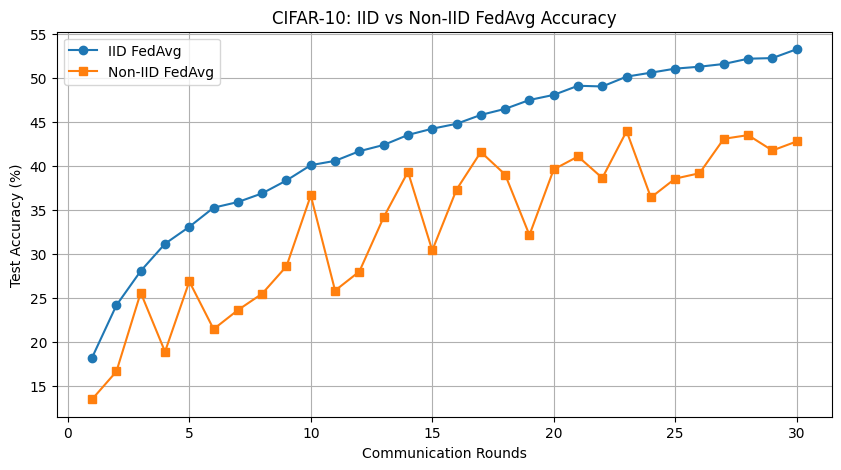

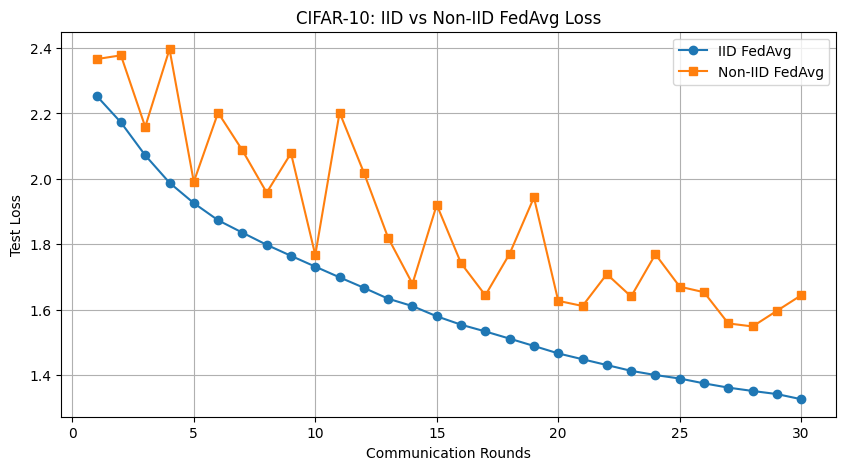

In [55]:

rounds = range(1, NUM_ROUNDS + 1)

plt.figure(figsize=(10, 5))

plt.plot(rounds, cifar_iid_accuracies,
         marker="o", label="IID FedAvg")

plt.plot(rounds, cifar_noniid_accuracies,
         marker="s", label="Non-IID FedAvg")

plt.xlabel("Communication Rounds")
plt.ylabel("Test Accuracy (%)")
plt.title("CIFAR-10: IID vs Non-IID FedAvg Accuracy")
plt.legend()
plt.grid(True)
plt.show()


plt.figure(figsize=(10, 5))

plt.plot(rounds, cifar_iid_losses,
         marker="o", label="IID FedAvg")

plt.plot(rounds, cifar_noniid_losses,
         marker="s", label="Non-IID FedAvg")

plt.xlabel("Communication Rounds")
plt.ylabel("Test Loss")
plt.title("CIFAR-10: IID vs Non-IID FedAvg Loss")
plt.legend()
plt.grid(True)
plt.show()


In [56]:

cifar_iid_noniid_results = pd.DataFrame({
    "Experiment": ["IID FedAvg", "Non-IID FedAvg"],
    "Final Test Loss": [
        cifar_iid_losses[-1],
        cifar_noniid_losses[-1]
    ],
    "Final Test Accuracy (%)": [
        cifar_iid_accuracies[-1],
        cifar_noniid_accuracies[-1]
    ]
})

display(cifar_iid_noniid_results)


,Experiment,Final Test Loss,Final Test Accuracy (%)
0,IID FedAvg,1.325519,53.3
1,Non-IID FedAvg,1.643528,42.8


In [58]:

alpha_values = [0.1, 0.5]

alpha_results = {}

ALPHA_ROUNDS = 30

for alpha in alpha_values:

    print("\n" + "=" * 50)
    print(f"Running FedAvg with alpha = {alpha}")
    print("=" * 50)

    partition = dirichlet_partition(
        train_dataset,
        num_clients=NUM_CLIENTS,
        alpha=alpha,
        min_samples_per_client=50,
        seed=SEED
    )

    model, losses, accuracies = run_fedavg(
        model_class=CIFAR10_CNN,
        train_dataset=train_dataset,
        test_dataset=test_dataset,
        partition=partition,
        initial_weights=initial_cifar_weights,
        rounds=ALPHA_ROUNDS,
        client_fraction=CLIENT_FRACTION,
        local_epochs=LOCAL_EPOCHS,
        batch_size=BATCH_SIZE,
        learning_rate=LEARNING_RATE
    )

    alpha_results[alpha] = {
        "model": model,
        "losses": losses,
        "accuracies": accuracies
    }

    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()



Running FedAvg with alpha = 0.1
Round 1/30 | Loss: 2.3203 | Accuracy: 13.60%
Round 2/30 | Loss: 2.6364 | Accuracy: 10.16%
Round 3/30 | Loss: 2.8532 | Accuracy: 15.42%
Round 4/30 | Loss: 2.5001 | Accuracy: 16.31%
Round 5/30 | Loss: 2.7512 | Accuracy: 12.72%
Round 6/30 | Loss: 2.5146 | Accuracy: 14.68%
Round 7/30 | Loss: 2.3788 | Accuracy: 14.94%
Round 8/30 | Loss: 2.4052 | Accuracy: 16.51%
Round 9/30 | Loss: 2.2476 | Accuracy: 20.49%
Round 10/30 | Loss: 2.4574 | Accuracy: 17.99%
Round 11/30 | Loss: 2.4593 | Accuracy: 14.83%
Round 12/30 | Loss: 2.2182 | Accuracy: 18.31%
Round 13/30 | Loss: 2.0121 | Accuracy: 24.90%
Round 14/30 | Loss: 2.1713 | Accuracy: 22.82%
Round 15/30 | Loss: 1.9719 | Accuracy: 33.35%
Round 16/30 | Loss: 1.9351 | Accuracy: 28.39%
Round 17/30 | Loss: 2.0426 | Accuracy: 21.13%
Round 18/30 | Loss: 1.9610 | Accuracy: 29.85%
Round 19/30 | Loss: 2.6951 | Accuracy: 16.34%
Round 20/30 | Loss: 2.1135 | Accuracy: 26.18%
Round 21/30 | Loss: 1.9799 | Accuracy: 27.11%
Round 22/3

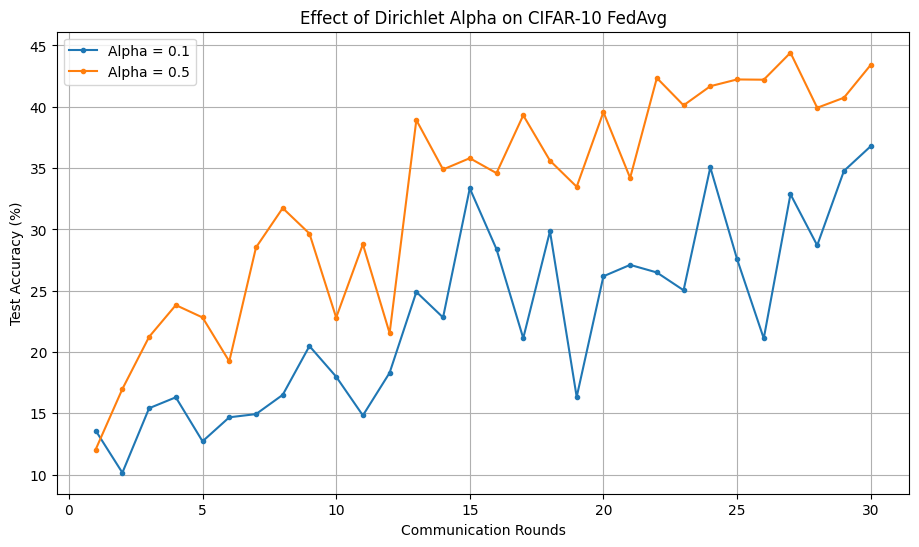

In [60]:

plt.figure(figsize=(11, 6))

for alpha in alpha_values:

    plt.plot(
        range(1, ALPHA_ROUNDS + 1),
        alpha_results[alpha]["accuracies"],
        marker="o",
        markersize=3,
        label=f"Alpha = {alpha}"
    )

plt.xlabel("Communication Rounds")
plt.ylabel("Test Accuracy (%)")
plt.title("Effect of Dirichlet Alpha on CIFAR-10 FedAvg")
plt.legend()
plt.grid(True)
plt.show()


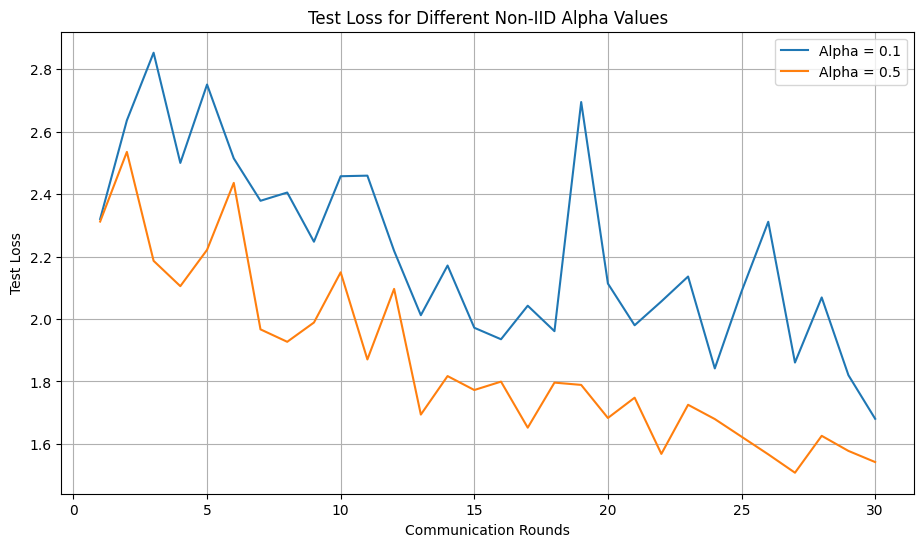

In [61]:

plt.figure(figsize=(11, 6))

for alpha in alpha_values:

    plt.plot(
        range(1, ALPHA_ROUNDS + 1),
        alpha_results[alpha]["losses"],
        label=f"Alpha = {alpha}"
    )

plt.xlabel("Communication Rounds")
plt.ylabel("Test Loss")
plt.title("Test Loss for Different Non-IID Alpha Values")
plt.legend()
plt.grid(True)
plt.show()


In [62]:

alpha_summary = pd.DataFrame([
    {
        "Alpha": alpha,
        "Final Test Loss": alpha_results[alpha]["losses"][-1],
        "Final Test Accuracy (%)":
            alpha_results[alpha]["accuracies"][-1]
    }
    for alpha in alpha_values
])

display(alpha_summary)


,Alpha,Final Test Loss,Final Test Accuracy (%)
0,0.1,1.680283,36.78
1,0.5,1.541600,43.41


**Non-IID FedSVG**

In [63]:

def compute_client_gradient(
    global_model,
    dataset,
    indices,
    batch_size=128
):

    global_model.train()

    loader = DataLoader(
        Subset(dataset, indices),
        batch_size=batch_size,
        shuffle=False,
        num_workers=0
    )

    criterion = nn.CrossEntropyLoss(reduction="sum")

    global_model.zero_grad(set_to_none=True)

    total_samples = 0

    for images, labels in loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = global_model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        total_samples += labels.size(0)

    local_gradients = {}

    for name, parameter in global_model.named_parameters():

        local_gradients[name] = (
            parameter.grad.detach().clone() / total_samples
        )

    return local_gradients, total_samples


In [64]:

def aggregate_gradients(
    global_model,
    client_gradients,
    client_sizes
):

    total_samples = sum(client_sizes)

    aggregated_gradients = {}

    for name, parameter in global_model.named_parameters():

        aggregated_gradients[name] = torch.zeros_like(
            parameter
        )

        for i in range(len(client_gradients)):

            weight = client_sizes[i] / total_samples

            aggregated_gradients[name] += (
                client_gradients[i][name] * weight
            )

    return aggregated_gradients


In [65]:

def update_global_model(
    global_model,
    aggregated_gradients,
    learning_rate
):

    with torch.no_grad():

        for name, parameter in global_model.named_parameters():

            parameter -= (
                learning_rate * aggregated_gradients[name]
            )


In [66]:

def run_fedsgd(
    model_class,
    train_dataset,
    test_dataset,
    partition,
    initial_weights,
    rounds=30,
    client_fraction=0.1,
    learning_rate=0.01,
    gradient_batch_size=128
):

    global_model = model_class().to(device)

    global_model.load_state_dict(
        copy.deepcopy(initial_weights)
    )

    num_clients = len(partition)

    num_selected = max(
        1, int(client_fraction * num_clients)
    )

    losses = []
    accuracies = []

    for round_num in range(rounds):

        selected_clients = random.sample(
            range(num_clients),
            num_selected
        )

        client_gradients = []
        client_sizes = []

        for client_id in selected_clients:

            gradients, size = compute_client_gradient(
                global_model,
                train_dataset,
                partition[client_id],
                batch_size=gradient_batch_size
            )

            client_gradients.append(gradients)
            client_sizes.append(size)

        # Server aggregates gradients
        aggregated_gradients = aggregate_gradients(
            global_model,
            client_gradients,
            client_sizes
        )

        # Server performs one global update
        update_global_model(
            global_model,
            aggregated_gradients,
            learning_rate
        )

        test_loss, test_accuracy = evaluate_model(
            global_model,
            test_dataset
        )

        losses.append(test_loss)
        accuracies.append(test_accuracy)

        print(
            f"Round {round_num + 1}/{rounds} | "
            f"Loss: {test_loss:.4f} | "
            f"Accuracy: {test_accuracy:.2f}%"
        )

        del client_gradients
        del aggregated_gradients

        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    return global_model, losses, accuracies


In [67]:

cifar_noniid_fedsgd_model, cifar_noniid_fedsgd_losses, cifar_noniid_fedsgd_accuracies = run_fedsgd(
    model_class=CIFAR10_CNN,
    train_dataset=train_dataset,
    test_dataset=test_dataset,
    partition=cifar_noniid_partition,
    initial_weights=initial_cifar_weights,
    rounds=NUM_ROUNDS,
    client_fraction=CLIENT_FRACTION,
    learning_rate=LEARNING_RATE,
    gradient_batch_size=128
)


Round 1/30 | Loss: 2.3030 | Accuracy: 10.67%
Round 2/30 | Loss: 2.3026 | Accuracy: 10.27%
Round 3/30 | Loss: 2.3013 | Accuracy: 10.43%
Round 4/30 | Loss: 2.3002 | Accuracy: 10.55%
Round 5/30 | Loss: 2.3000 | Accuracy: 11.30%
Round 6/30 | Loss: 2.2987 | Accuracy: 11.67%
Round 7/30 | Loss: 2.2985 | Accuracy: 11.59%
Round 8/30 | Loss: 2.2970 | Accuracy: 12.91%
Round 9/30 | Loss: 2.2960 | Accuracy: 13.27%
Round 10/30 | Loss: 2.2961 | Accuracy: 12.99%
Round 11/30 | Loss: 2.2938 | Accuracy: 13.58%
Round 12/30 | Loss: 2.2929 | Accuracy: 13.59%
Round 13/30 | Loss: 2.2921 | Accuracy: 13.77%
Round 14/30 | Loss: 2.2913 | Accuracy: 13.52%
Round 15/30 | Loss: 2.2908 | Accuracy: 13.53%
Round 16/30 | Loss: 2.2896 | Accuracy: 12.37%
Round 17/30 | Loss: 2.2883 | Accuracy: 15.21%
Round 18/30 | Loss: 2.2879 | Accuracy: 14.09%
Round 19/30 | Loss: 2.2871 | Accuracy: 15.38%
Round 20/30 | Loss: 2.2868 | Accuracy: 16.22%
Round 21/30 | Loss: 2.2858 | Accuracy: 15.54%
Round 22/30 | Loss: 2.2851 | Accuracy: 17.2

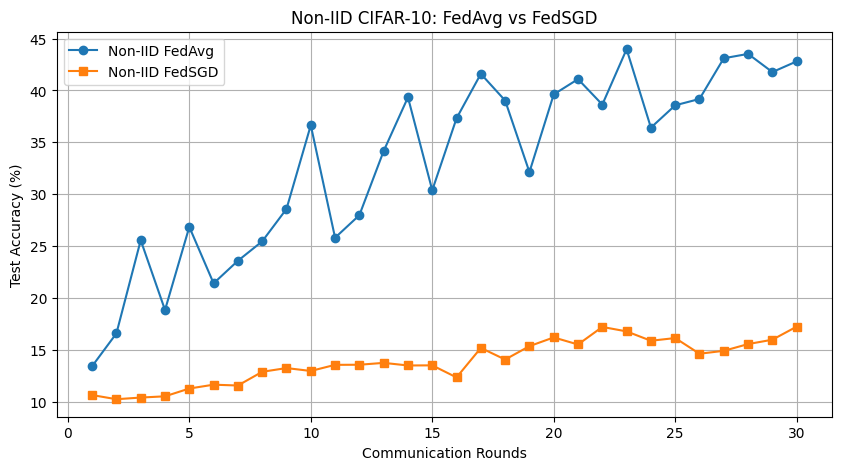

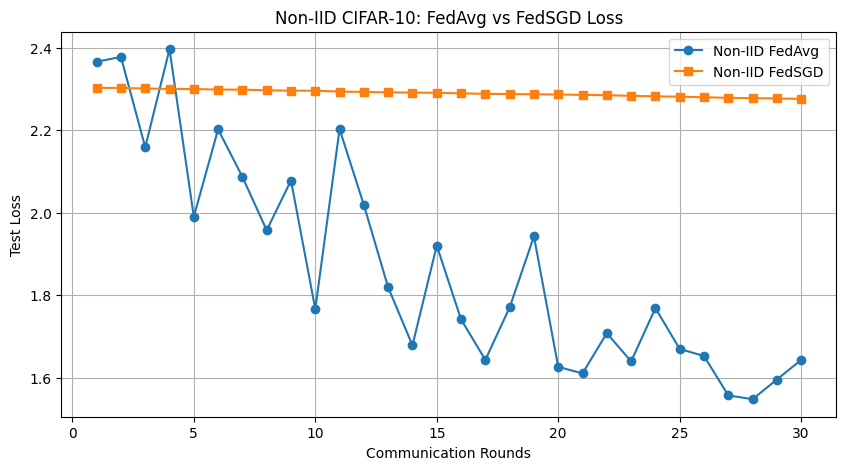

In [68]:

plt.figure(figsize=(10, 5))

plt.plot(
    range(1, NUM_ROUNDS + 1),
    cifar_noniid_accuracies,
    label="Non-IID FedAvg",
    marker="o"
)

plt.plot(
    range(1, NUM_ROUNDS + 1),
    cifar_noniid_fedsgd_accuracies,
    label="Non-IID FedSGD",
    marker="s"
)

plt.xlabel("Communication Rounds")
plt.ylabel("Test Accuracy (%)")
plt.title("Non-IID CIFAR-10: FedAvg vs FedSGD")
plt.legend()
plt.grid(True)
plt.show()


plt.figure(figsize=(10, 5))

plt.plot(
    range(1, NUM_ROUNDS + 1),
    cifar_noniid_losses,
    label="Non-IID FedAvg",
    marker="o"
)

plt.plot(
    range(1, NUM_ROUNDS + 1),
    cifar_noniid_fedsgd_losses,
    label="Non-IID FedSGD",
    marker="s"
)

plt.xlabel("Communication Rounds")
plt.ylabel("Test Loss")
plt.title("Non-IID CIFAR-10: FedAvg vs FedSGD Loss")
plt.legend()
plt.grid(True)
plt.show()
